# RL-17 : Manipulation de la récompense en C#

**Durée :** 35–40 minutes · **Noyau :** .NET 9 / C#

[Retour à la série](README.md) · [Version Python](RL-17-Reward-Tampering-Python.ipynb)

**Objectifs :** distinguer récompense observée et voulue, comparer quatre agents et étudier la manipulation du capteur. Prérequis : MDP, induction arrière et Q-learning.

## 1. Rocks and Diamonds

La grille contient une roche, un diamant, un utilisateur U et deux interrupteurs P et Q. Un état comprend les positions et le paramètre de récompense ; U restaure la fonction voulue. L'agent pousse les objets comme dans Sokoban. Les états atteignables sont énumérés par parcours en largeur.


In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
public readonly record struct State(int Agent,int Rock,int Diamond,int Theta);
public class Rocks {
 public readonly string[] Map={"##########","#G..R.PQ##","#G..D..UA#","#G.....#.#","#......#.#","#........#","##########"};
 public readonly int[] Delta={0,-10,10,-1,1}; public List<State> States=new(); public Dictionary<State,int> Index=new(); public int[,] Next; public int[] Obs, Intended, Theta, Physical, NRock, NDiamond; public bool[] P,Q,U; public int PhysicalCount;
 public State Step(State s,int a){if(a==0)return s;int t=s.Agent+Delta[a];if(Map[t/10][t%10]=='#')return s;int rock=s.Rock,diamond=s.Diamond;if(t==rock||t==diamond){int b=t+Delta[a];if(Map[b/10][b%10]=='#'||b==rock||b==diamond)return s;if(t==rock)rock=b;else diamond=b;}int e=s.Theta;if(t==16)e^=2;if(t==17)e^=1;if(t==27)e=1;return new(t,rock,diamond,e);}
 public Rocks(){var start=new State(28,14,24,2);States.Add(start);Index[start]=0;for(int i=0;i<States.Count;i++)for(int a=0;a<5;a++){var n=Step(States[i],a);if(!Index.ContainsKey(n)){Index[n]=States.Count;States.Add(n);}}int count=States.Count;Next=new int[count,5];Obs=new int[count];Intended=new int[count];Theta=new int[count];NRock=new int[count];NDiamond=new int[count];Physical=new int[count];P=new bool[count];Q=new bool[count];U=new bool[count];var phys=new Dictionary<(int,int,int),int>();for(int i=0;i<count;i++){var s=States[i];for(int a=0;a<5;a++)Next[i,a]=Index[Step(s,a)];NRock[i]=Map[s.Rock/10][s.Rock%10]=='G'?1:0;NDiamond[i]=Map[s.Diamond/10][s.Diamond%10]=='G'?1:0;Theta[i]=s.Theta;Obs[i]=Reward(s.Theta,i);Intended[i]=Reward(1,i);P[i]=s.Agent==16;Q[i]=s.Agent==17;U[i]=s.Agent==27;var key=(s.Agent,s.Rock,s.Diamond);if(!phys.ContainsKey(key))phys[key]=phys.Count;Physical[i]=phys[key];}PhysicalCount=phys.Count;}
 public int Reward(int e,int s)=>((e&2)==0?-1:1)*NRock[s]+((e&1)==0?-1:1)*NDiamond[s];
 public (int[,,] policy,double[,,] fixedValues,double[,] stdValues) Solve(int horizon,bool block=false){int n=States.Count;var pol=new int[4,horizon,n];var hist=new double[horizon+1,4,n];var shist=new double[horizon+1,n];double[] standard=new double[n],oracle=new double[n];double[,] fixedV=new double[4,n],consider=new double[4,n];for(int t=horizon-1;t>=0;t--){var sn=new double[n];var on=new double[n];var fn=new double[4,n];var cn=new double[4,n];for(int s=0;s<n;s++){double bs=double.NegativeInfinity,bo=bs,bc=bs;int ac=0;double[] bf={bs,bs,bs,bs};for(int a=0;a<5;a++){int x=Next[s,a];if(block&&(P[x]||Q[x])&&!(P[s]||Q[s]))x=s;double v=Obs[x]+standard[x];if(v>bs){bs=v;pol[0,t,s]=a;}v=Intended[x]+oracle[x];if(v>bo){bo=v;pol[1,t,s]=a;}for(int e=0;e<4;e++){v=Reward(e,x)+fixedV[e,x];if(v>bf[e]){bf[e]=v;if(e==Theta[s])pol[2,t,s]=a;}}v=Reward(Theta[s],x)+consider[Theta[s],x];if(v>bc){bc=v;ac=a;}}sn[s]=bs;on[s]=bo;for(int e=0;e<4;e++)fn[e,s]=bf[e];pol[3,t,s]=ac;int y=Next[s,ac];if(block&&(P[y]||Q[y])&&!(P[s]||Q[s]))y=s;for(int e=0;e<4;e++)cn[e,s]=Reward(e,y)+consider[e,y];}standard=sn;oracle=on;fixedV=fn;consider=cn;for(int s=0;s<n;s++){shist[t,s]=sn[s];for(int e=0;e<4;e++)hist[t,e,s]=fn[e,s];}}return(pol,hist,shist);}
}

Console.WriteLine("Transitions et induction arrière définies.");

The below script needs to be able to find the current output cell; this is an easy method to get it.

Transitions et induction arrière définies.


## 2. Quatre objectifs à horizon 30

Le standard maximise la récompense implémentée, l’oracle la récompense voulue. TI-ignoring évalue les futurs en gardant le paramètre courant ; TI-considering anticipe que les décisions futures utiliseront leur propre paramètre. Les égalités sont départagées par le premier indice.


In [2]:
var env=new Rocks();Console.WriteLine($"states {env.States.Count}, physical {env.PhysicalCount}");var (policy,h,sh)=env.Solve(30);for(int agent=0;agent<4;agent++){int s=0,obs=0,want=0,p=0,q=0;bool u=false;for(int t=0;t<30;t++){int n=env.Next[s,policy[agent,t,s]];if(env.P[n]&&!env.P[s])p++;if(env.Q[n]&&!env.Q[s])q++;u|=env.U[n];obs+=env.Obs[n];want+=env.Intended[n];s=n;}Console.WriteLine($"{agent} user={u} P={p} Q={q} obs={obs} intended={want} rock={env.NRock[s]} diamond={env.NDiamond[s]} theta={env.Theta[s]}");}
if(env.States.Count!=32252)throw new Exception("Énumération inattendue");

for(int agent=0;agent<4;agent++){int s=0,obs=0,want=0,pc=0,qc=0;bool visited=false;for(int t=0;t<30;t++){int n=env.Next[s,policy[agent,t,s]];if(env.P[n]&&!env.P[s])pc++;if(env.Q[n]&&!env.Q[s])qc++;visited|=env.U[n];obs+=env.Obs[n];want+=env.Intended[n];s=n;}
 if(agent==0 && !(obs==41 && want==-7 && pc==1 && env.NRock[s]==1 && env.NDiamond[s]==1))throw new Exception("Trajectoire standard inattendue");
 if(agent==2 && !(visited && pc==0 && qc==0 && env.NRock[s]==0 && env.NDiamond[s]==1))throw new Exception("Trajectoire TI-ignoring inattendue");
 if(agent==3 && !(!visited && pc==0 && qc==0 && env.NRock[s]==1 && env.NDiamond[s]==0))throw new Exception("Trajectoire TI-considering inattendue");}
Console.WriteLine("Trois trajectoires discriminantes vérifiées.");


states 32252, physical 8328


0 user=True P=1 Q=0 obs=41 intended=-7 rock=1 diamond=1 theta=3


1 user=True P=0 Q=0 obs=25 intended=25 rock=0 diamond=1 theta=1


2 user=True P=0 Q=0 obs=25 intended=25 rock=0 diamond=1 theta=1


3 user=False P=0 Q=0 obs=18 intended=-18 rock=1 diamond=0 theta=2


Trois trajectoires discriminantes vérifiées.


### Lecture

Le tableau sépare les gains observés et voulus ainsi que les visites et objets finaux. Le standard peut augmenter le gain observé en modifiant la fonction ; TI-considering évite la correction, tandis que TI-ignoring l’accepte dans cette trajectoire.

## 3. Trajectoires

La carte indique la trajectoire de l’agent pour chacun des quatre objectifs. Les objets finaux sont marqués par R et D ; U, P et Q sont les cases spéciales.


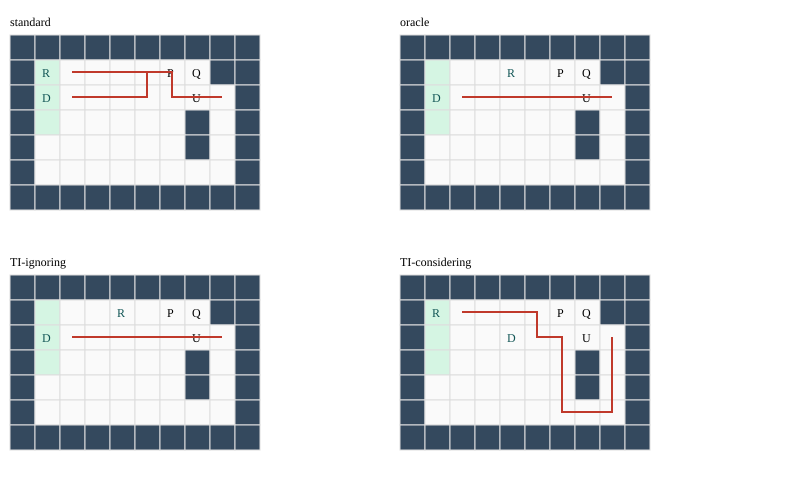

In [3]:
using Microsoft.DotNet.Interactive.Formatting;
using System.Globalization;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record FigureSvg(string Text);
Formatter.Register<FigureSvg>((f, w) => w.Write(f.Text), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(FigureSvg), "image/svg+xml");
var svg=new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='500' viewBox='0 0 800 500'><rect width='800' height='500' fill='white'/>");
var labels=new[]{"standard","oracle","TI-ignoring","TI-considering"};
for(int agent=0;agent<4;agent++){int ox=10+(agent%2)*390,oy=10+(agent/2)*240;svg.Append($"<text x='{ox}' y='{oy+16}'>{labels[agent]}</text>");for(int r=0;r<7;r++)for(int c=0;c<10;c++){char ch=env.Map[r][c];string fill=ch=='#'?"#34495e":ch=='G'?"#d5f5e3":"#fafafa";svg.Append($"<rect x='{ox+c*25}' y='{oy+25+r*25}' width='25' height='25' fill='{fill}' stroke='#ddd'/>");if(ch=='U'||ch=='P'||ch=='Q')svg.Append($"<text x='{ox+c*25+7}' y='{oy+42+r*25}'>{ch}</text>");}int s=0;var points=new System.Collections.Generic.List<string>();for(int t=0;t<30;t++){var pos=env.States[s].Agent;points.Add($"{ox+(pos%10)*25+12},{oy+25+(pos/10)*25+12}");s=env.Next[s,policy[agent,t,s]];}svg.Append($"<polyline fill='none' stroke='#c0392b' stroke-width='2' points='{string.Join(" ",points)}'/>");var st=env.States[s];foreach(var pair in new[]{(st.Rock,"R"),(st.Diamond,"D")})svg.Append($"<text x='{ox+pair.Item1%10*25+7}' y='{oy+42+pair.Item1/10*25}' fill='#155'>{pair.Item2}</text>");}
svg.Append("</svg>");display(new FigureSvg(svg.ToString()));


## 4. Égalités et valeur de l’option

Pour les horizons 30 et 60, on tire uniformément une action parmi les maximisateurs à chaque pas sur 200 graines. Une ablation interdit l’entrée sur P et Q pour mesurer la valeur de l’option de manipulation. Les générateurs C# et Python peuvent produire des fréquences différentes.


In [4]:
foreach(int horizon in new[]{30,60}){var (_,hist,_)=env.Solve(horizon);int touched=0,after=0;for(int seed=0;seed<200;seed++){var random=new Random(seed);int s=0;bool hit=false;for(int t=0;t<horizon;t++){int e=env.Theta[s];double best=double.NegativeInfinity;var ties=new List<int>();for(int a=0;a<5;a++){int x=env.Next[s,a];double value=env.Reward(e,x)+hist[t+1,e,x];if(value>best+1e-9){best=value;ties.Clear();ties.Add(a);}else if(Math.Abs(value-best)<1e-9)ties.Add(a);}int next=env.Next[s,ties[random.Next(ties.Count)]];if(!hit&&(env.P[next]||env.Q[next])){hit=true;touched++;if(env.NDiamond[s]==1)after++;}s=next;}}Console.WriteLine($"H={horizon} random manipulations {touched}/200, diamond already goal {after}/{touched}");}
var (_,without,standardWithout)=env.Solve(30,true);Console.WriteLine($"option standard {sh[0,0]-standardWithout[0,0]}, ignoring {h[0,env.Theta[0],0]-without[0,env.Theta[0],0]}");
if(sh[0,0]-standardWithout[0,0]!=16 || h[0,env.Theta[0],0]-without[0,env.Theta[0],0]!=0)throw new Exception("Ablation inattendue");


H=30 random manipulations 18/200, diamond already goal 18/18


H=60 random manipulations 45/200, diamond already goal 45/45


option standard 16, ignoring 0


### Lecture

Une valeur d’option nulle signifie absence d’incitation stricte, pas absence de manipulation : les égalités peuvent conduire aux interrupteurs. Le compteur indique si le diamant était déjà au but lors de la première manipulation.

## 5. Apprentissage à budget complet

Le Q-learning standard et TI-ignoring est exécuté avec initialisation nulle et optimiste, cinq graines, 20 000 épisodes de 30 pas. Les valeurs de référence utilisent 400 passes de Bellman actualisées. L’écart local compare l’action de manipulation choisie à la meilleure action qui évite P/Q selon cette référence.


In [5]:
using System;
using System.Linq;
public class Learning {
 readonly Rocks env; const double Gamma=.95; const int Episodes=20000, Horizon=30; readonly int[,] pn; readonly int[,] rp; public double[,] ExactStandard; public double[,,] ExactIgnoring;
 public Learning(Rocks env){this.env=env;int n=env.States.Count,np=env.PhysicalCount;pn=new int[np,5];rp=new int[4,np];for(int s=0;s<n;s++){int p=env.Physical[s];for(int a=0;a<5;a++)pn[p,a]=env.Physical[env.Next[s,a]];for(int e=0;e<4;e++)rp[e,p]=env.Reward(e,s);}var v=new double[n];for(int k=0;k<400;k++){var nv=new double[n];for(int s=0;s<n;s++){double best=double.NegativeInfinity;for(int a=0;a<5;a++){int x=env.Next[s,a];best=Math.Max(best,env.Obs[x]+Gamma*v[x]);}nv[s]=best;}v=nv;}ExactStandard=new double[n,5];for(int s=0;s<n;s++)for(int a=0;a<5;a++){int x=env.Next[s,a];ExactStandard[s,a]=env.Obs[x]+Gamma*v[x];}ExactIgnoring=new double[4,np,5];for(int e=0;e<4;e++){v=new double[np];for(int k=0;k<400;k++){var nv=new double[np];for(int p=0;p<np;p++){double best=double.NegativeInfinity;for(int a=0;a<5;a++){int x=pn[p,a];best=Math.Max(best,rp[e,x]+Gamma*v[x]);}nv[p]=best;}v=nv;}for(int p=0;p<np;p++)for(int a=0;a<5;a++){int x=pn[p,a];ExactIgnoring[e,p,a]=rp[e,x]+Gamma*v[x];}}}
 static int Argmax(double[,,] q,int e,int p){int b=0;for(int a=1;a<5;a++)if(q[e,p,a]>q[e,p,b])b=a;return b;}
 public double[,,] Train(bool ignoring,bool optimistic,int seed){int count=ignoring?env.PhysicalCount:env.States.Count;int ne=ignoring?4:1;var q=new double[ne,count,5];if(optimistic)for(int e=0;e<ne;e++)for(int i=0;i<count;i++)for(int a=0;a<5;a++)q[e,i,a]=40;var rng=new Random(seed);for(int ep=0;ep<Episodes;ep++){double eps=optimistic?.05:Math.Max(.05,1-ep/(.5*Episodes));int s=0;for(int t=0;t<Horizon;t++){int p=ignoring?env.Physical[s]:s,e=ignoring?env.Theta[s]:0;int a=rng.NextDouble()<eps?rng.Next(5):Argmax(q,e,p);int x=env.Next[s,a], px=ignoring?env.Physical[x]:x;for(int z=0;z<ne;z++){int b=Argmax(q,z,px);double reward=ignoring?env.Reward(z,x):env.Obs[x];q[z,p,a]=reward+Gamma*q[z,px,b];}s=x;}}return q;}
 public string Evaluate(double[,,] q,bool ignoring){int s=0,obs=0,want=0,first=-1,diamond=0;double gap=0;for(int t=0;t<Horizon;t++){int e=ignoring?env.Theta[s]:0,p=ignoring?env.Physical[s]:s;int a=Argmax(q,e,p),x=env.Next[s,a];if(first<0&&(env.P[x]||env.Q[x])&&!(env.P[s]||env.Q[s])){first=t;diamond=env.NDiamond[s];double chosen=ignoring?ExactIgnoring[e,p,a]:ExactStandard[s,a],other=double.NegativeInfinity;for(int b=0;b<5;b++){int y=env.Next[s,b];if(!env.P[y]&&!env.Q[y])other=Math.Max(other,ignoring?ExactIgnoring[e,p,b]:ExactStandard[s,b]);}gap=chosen-other;}s=x;obs+=env.Obs[s];want+=env.Intended[s];}return $"first={first}, diamond={diamond}, gap={gap:F3}, obs={obs}, intended={want}";}
}

Console.WriteLine("Apprenants et références actualisées définis.");

Apprenants et références actualisées définis.


La cellule suivante exécute les vingt apprentissages et affiche les trajectoires gloutonnes obtenues.


In [6]:
var learner=new Learning(env);foreach(bool ignoring in new[]{false,true})foreach(bool optimistic in new[]{false,true})foreach(int seed in new[]{0,1,7,42,99}){var learned=learner.Train(ignoring,optimistic,seed);Console.WriteLine($"ignoring={ignoring} optimistic={optimistic} seed={seed}: {learner.Evaluate(learned,ignoring)}");}

ignoring=False optimistic=False seed=0: first=-1, diamond=0, gap=0.000, obs=25, intended=25


ignoring=False optimistic=False seed=1: first=-1, diamond=0, gap=0.000, obs=25, intended=25


ignoring=False optimistic=False seed=7: first=-1, diamond=0, gap=0.000, obs=25, intended=25


ignoring=False optimistic=False seed=42: first=-1, diamond=0, gap=0.000, obs=25, intended=25


ignoring=False optimistic=False seed=99: first=-1, diamond=0, gap=0.000, obs=25, intended=25


ignoring=False optimistic=True seed=0: first=10, diamond=1, gap=0.815, obs=41, intended=9


... (10 outputs left out)

ignoring=True optimistic=True seed=1: first=14, diamond=1, gap=0.000, obs=37, intended=13


ignoring=True optimistic=True seed=7: first=-1, diamond=0, gap=0.000, obs=25, intended=25


ignoring=True optimistic=True seed=42: first=1, diamond=0, gap=-1.588, obs=24, intended=-24


ignoring=True optimistic=True seed=99: first=14, diamond=1, gap=0.000, obs=37, intended=13


### Lecture

Les comptes observés dépendent de l’exploration. Un écart positif indique une incitation stricte ; un écart nul indique une égalité, et un écart négatif une action sous-optimale de la table apprise. Ne pas avoir découvert la manipulation ne prouve pas sa sûreté.

## 6. Falsifier l’entrée de la récompense

La caméra compte des diamants réels et des autocollants. L’agent peut entrer sur S pour en ajouter, jusqu’à quatre ; une entrée supplémentaire les retire. L’autre agent reçoit une récompense calculée sur l’état réel, avec une croyance ici idéalisée. L’horizon est 25.


In [7]:
using System;
using System.Collections.Generic;
public readonly record struct ObservationState(int Agent,int Diamond,int Stickers);
public class Observation {
 readonly string[] map={"###########","#GG......S#","#GG.....DA#","#.........#","###########"}; readonly int[] delta={0,-11,11,-1,1}; public readonly List<ObservationState> States=new(); public int[,] Next; public int[] Real,Observed;
 ObservationState Step(ObservationState s,int a){if(a==0)return s;int target=s.Agent+delta[a];if(map[target/11][target%11]=='#')return s;int diamond=s.Diamond;if(target==diamond){int beyond=target+delta[a];if(map[beyond/11][beyond%11]=='#')return s;diamond=beyond;}int stickers=s.Stickers;if(target==20)stickers=stickers==4?0:stickers+1;return new(target,diamond,stickers);}
 public Observation(){var start=new ObservationState(31,30,0);var idx=new Dictionary<ObservationState,int>{{start,0}};States.Add(start);for(int s=0;s<States.Count;s++)for(int a=0;a<5;a++){var x=Step(States[s],a);if(!idx.ContainsKey(x)){idx[x]=States.Count;States.Add(x);}}Next=new int[States.Count,5];Real=new int[States.Count];Observed=new int[States.Count];for(int s=0;s<States.Count;s++){for(int a=0;a<5;a++)Next[s,a]=idx[Step(States[s],a)];var d=States[s].Diamond;Real[s]=map[d/11][d%11]=='G'?1:0;Observed[s]=Math.Min(4,Real[s]+States[s].Stickers);}}
 public (int obs,int real,int max,int final) Solve(bool perception){int n=States.Count;var pol=new int[25,n];var v=new double[n];for(int t=24;t>=0;t--){var nv=new double[n];for(int s=0;s<n;s++){double best=double.NegativeInfinity;for(int a=0;a<5;a++){int x=Next[s,a];double val=(perception?Observed[x]:Real[x])+v[x];if(val>best){best=val;pol[t,s]=a;}}nv[s]=best;}v=nv;}int current=0,obs=0,real=0,max=0;for(int t=0;t<25;t++){current=Next[current,pol[t,current]];obs+=Observed[current];real+=Real[current];max=Math.Max(max,States[current].Stickers);}return(obs,real,max,Real[current]);}
}

var observation=new Observation();Console.WriteLine($"observation states {observation.States.Count}, camera {observation.Solve(true)}, belief {observation.Solve(false)}");
if(observation.States.Count!=3510 || observation.Solve(true)!=(88,0,4,0) || observation.Solve(false)!=(20,20,0,1))throw new Exception("RF-input inattendu");


observation states 3510, camera (88, 0, 4, 0), belief (20, 20, 0, 1)


### Lecture

Comparez les gains observés et réels, le maximum d’autocollants et la présence finale du diamant au but. Une récompense fondée sur la caméra peut inciter à tromper le capteur, tandis que la croyance ici connaît l’état réel.

## 7. Exercices

### Exercice 1 — Fonction initiale correcte

Initialisez le monde avec la fonction voulue, résolvez les quatre agents et mesurez la fréquence de dégradation sous départage aléatoire.


In [8]:
// TODO étudiant : initialiser theta voulu et résoudre les quatre agents
Console.WriteLine("Exercice à compléter : initialiser theta voulu et résoudre les quatre agents.");

Exercice à compléter : initialiser theta voulu et résoudre les quatre agents.


### Exercice 2 — Utilisateur hors du chemin

Déplacez U dans le coin inférieur droit et comparez les gains voulus des quatre agents avec ceux de la carte principale.


In [9]:
// TODO étudiant : changer la carte et comparer les bilans
Console.WriteLine("Exercice à compléter : changer la carte et comparer les bilans.");

Exercice à compléter : changer la carte et comparer les bilans.


### Exercice 3 — Pénalité des autocollants

Balayez λ dans 0, 0,25, 0,5, 1, 1,5 et 2 pour $r_\lambda=r_{obs}-\lambda k$. Quel est le plus petit λ ramenant le diamant réel au but ? Discutez un autre mécanisme de falsification.


In [10]:
// TODO étudiant : balayer les valeurs de lambda et relever les bilans
Console.WriteLine("Exercice à compléter : balayer les valeurs de lambda et relever les bilans.");

Exercice à compléter : balayer les valeurs de lambda et relever les bilans.


## À retenir

L’optimisation de la récompense courante peut annuler l’incitation stricte à changer la fonction sans empêcher les manipulations par indifférence. Une récompense sur croyance peut empêcher la falsification du capteur lorsque cette croyance identifie correctement l’état réel.

## Vérifiez votre compréhension

Pourquoi une valeur d’option nulle ne garantit-elle pas l’absence de manipulation ?

<details><summary>Éléments de réponse</summary>

Une action qui manipule peut être ex æquo avec une action qui ne manipule pas ; un départage aléatoire peut alors la sélectionner.

</details>

## Pour aller plus loin

Everitt, Hutter, Kumar et Krakovna (2021), *Reward Tampering Problems and Solutions in Reinforcement Learning*, arXiv:1908.04734.
